# Week 2: Feature Engineering & Baseline Model Benchmark
**Project:** Telco Customer Churn Prediction & Retention Optimization  
**Deliverables:**
1. Clean data & domain-engineered feature pipeline (`tenure_bucket`, `avg_monthly_spend`, `services_count`, interaction ratios)
2. Handling class imbalance (~26.54% churn) via Class-Weighting and SMOTE
3. Logistic Regression Baseline benchmark with full metrics (ROC-AUC, PR-AUC, F1, Recall, Precision)
4. Serialized preprocessor and baseline model artifacts


In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)
from imblearn.over_sampling import SMOTE

from src.features import (
    clean_raw_data,
    create_engineered_features,
    prepare_train_test_data,
    apply_smote,
    NUMERIC_COLS,
    CATEGORICAL_COLS,
    ALL_SERVICE_COLS,
)

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")


## 1. Raw Data Ingestion & Data Quirk Remediation
- **Quirk #1:** `TotalCharges` stored as whitespace strings (`" "`) coerced to numeric with `$0.00` imputed for `tenure == 0`.
- **Quirk #2:** Collapsed `"No internet service"` and `"No phone service"` into `"No"`.


In [2]:
raw_df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(f"Raw dataset shape: {raw_df.shape}")

cleaned_df = clean_raw_data(raw_df)
print(f"TotalCharges nulls after coercion: {cleaned_df['TotalCharges'].isnull().sum()}")
print(f"TotalCharges dtype: {cleaned_df['TotalCharges'].dtype}")


Raw dataset shape: (7043, 21)
TotalCharges nulls after coercion: 0
TotalCharges dtype: float64


## 2. Feature Engineering Implementation
Creating:
1. `tenure_bucket`: 12-month lifecycle intervals (`0-12`, `13-24`, `25-36`, `37-48`, `49-60`, `61-72`).
2. `avg_monthly_spend`: Historical monthly burn rate ($	ext{TotalCharges} / 	ext{tenure}$).
3. `services_count`: Count of subscribed add-on services ($0$ to $8$).
4. `charge_ratio`: Current monthly charge relative to historical average spend.
5. `clv`: Customer Lifetime Value proxy ($	ext{MonthlyCharges} 	imes 	ext{tenure}$).
6. Service synergy flags: `has_support_security` and `has_streaming`.


In [3]:
fe_df = create_engineered_features(cleaned_df)
print("Engineered features sample:")
fe_df[["customerID", "tenure", "tenure_bucket", "MonthlyCharges", "avg_monthly_spend", "charge_ratio", "services_count", "clv"]].head()


Engineered features sample:


,customerID,tenure,tenure_bucket,MonthlyCharges,avg_monthly_spend,charge_ratio,services_count,clv
0,7590-VHVEG,1,0-12,29.85,29.850000,0.999997,1,29.85
1,5575-GNVDE,34,25-36,56.95,55.573529,1.024767,3,1936.30
2,3668-QPYBK,2,0-12,53.85,54.075000,0.995837,3,107.70
3,7795-CFOCW,45,37-48,42.30,40.905556,1.034087,3,1903.50
4,9237-HQITU,2,0-12,70.70,75.825000,0.932409,1,141.40


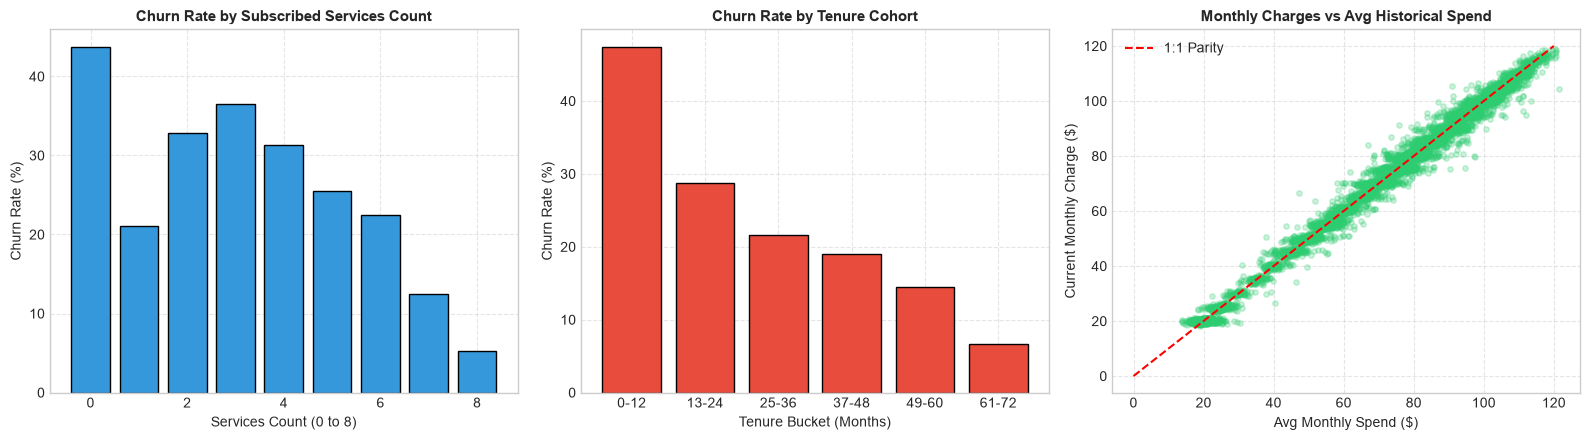

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Churn rate by services count
sc_churn = fe_df.groupby("services_count")["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
axes[0].bar(sc_churn.index, sc_churn.values, color="#3498db", edgecolor="black")
axes[0].set_title("Churn Rate by Subscribed Services Count", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Services Count (0 to 8)")
axes[0].set_ylabel("Churn Rate (%)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Churn rate by tenure bucket
tb_churn = fe_df.groupby("tenure_bucket", observed=False)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
axes[1].bar(tb_churn.index.astype(str), tb_churn.values, color="#e74c3c", edgecolor="black")
axes[1].set_title("Churn Rate by Tenure Cohort", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Tenure Bucket (Months)")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Monthly charges vs avg monthly spend
axes[2].scatter(fe_df["avg_monthly_spend"], fe_df["MonthlyCharges"], alpha=0.25, color="#2ecc71", s=15)
axes[2].plot([0, 120], [0, 120], color="red", linestyle="--", label="1:1 Parity")
axes[2].set_title("Monthly Charges vs Avg Historical Spend", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Avg Monthly Spend ($)")
axes[2].set_ylabel("Current Monthly Charge ($)")
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## 3. End-to-End Pipeline & Stratified Train/Test Split
Using `prepare_train_test_data` to perform leakage-free preprocessing:
- Fit `StandardScaler` strictly on 80% train set.
- Fit `OneHotEncoder(drop='first')` on categorical attributes.
- Ensure 26.54% churn rate is identical in train and test splits.


In [5]:
data = prepare_train_test_data(filepath="../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
X_train, X_test = data["X_train"], data["X_test"]
y_train, y_test = data["y_train"], data["y_test"]
feature_names = data["feature_names"]

print(f"X_train shape: {X_train.shape} | y_train churn rate: {y_train.mean():.4f}")
print(f"X_test shape:  {X_test.shape}  | y_test churn rate:  {y_test.mean():.4f}")
print(f"Number of engineered features: {len(feature_names)}")


X_train shape: (5634, 34) | y_train churn rate: 0.2654
X_test shape:  (1409, 34)  | y_test churn rate:  0.2654
Number of engineered features: 34


## 4. Addressing Class Imbalance: Vanilla vs Class-Weighted vs SMOTE
Evaluating 3 Logistic Regression strategies:
1. **Vanilla:** Default unweighted optimization.
2. **Class-Weighted (Balanced):** Dynamically penalizes errors on the minority class inversely proportional to class frequencies.
3. **SMOTE:** Synthetic Minority Over-sampling to balance the training distribution 50/50.


In [6]:
# 1. Vanilla
lr_vanilla = LogisticRegression(max_iter=1000, random_state=42)
lr_vanilla.fit(X_train, y_train)

# 2. Class-Weighted Balanced
lr_balanced = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
lr_balanced.fit(X_train, y_train)

# 3. SMOTE Resampled
X_train_smote, y_train_smote = apply_smote(X_train, y_train, random_state=42)
lr_smote = LogisticRegression(max_iter=1000, random_state=42)
lr_smote.fit(X_train_smote, y_train_smote)

# Evaluation function
def score_model(model, name):
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.50).astype(int)
    return {
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob),
        "F1-Score": f1_score(y_test, pred),
        "Recall (Sensitivity)": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Accuracy": accuracy_score(y_test, pred),
    }

benchmark_df = pd.DataFrame([
    score_model(lr_vanilla, "Logistic Regression (Vanilla)"),
    score_model(lr_balanced, "Logistic Regression (Class-Weighted Balanced)"),
    score_model(lr_smote, "Logistic Regression (SMOTE Resampled)"),
])

benchmark_df


,Model,ROC-AUC,PR-AUC,F1-Score,Recall (Sensitivity),Precision,Accuracy
0,Logistic Regression (Vanilla),0.843078,0.640674,0.590164,0.529412,0.666667,0.804826
1,Logistic Regression (Class-Weighted Balanced),0.843055,0.641825,0.612632,0.778075,0.505208,0.738822
2,Logistic Regression (SMOTE Resampled),0.840084,0.639258,0.620253,0.786096,0.512195,0.744500


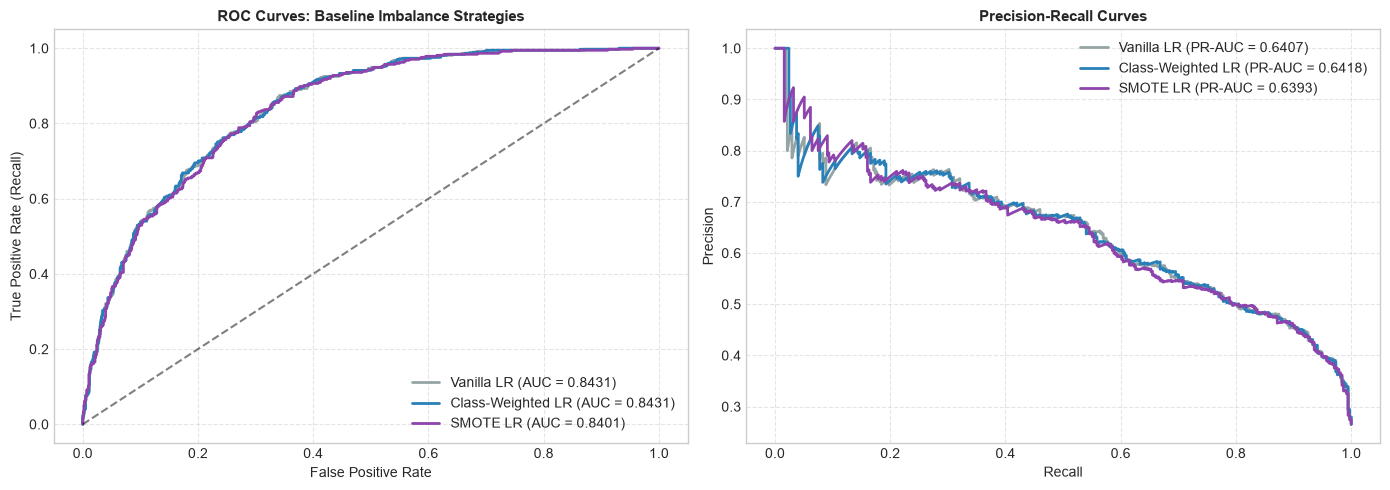

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = [
    (lr_vanilla, "Vanilla LR", "#95a5a6"),
    (lr_balanced, "Class-Weighted LR", "#2980b9"),
    (lr_smote, "SMOTE LR", "#8e44ad"),
]

# ROC Curves
for model, name, color in models:
    prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})", color=color, linewidth=2)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("ROC Curves: Baseline Imbalance Strategies", fontsize=11, fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Precision-Recall Curves
for model, name, color in models:
    prob = model.predict_proba(X_test)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, prob)
    pr_auc = average_precision_score(y_test, prob)
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC = {pr_auc:.4f})", color=color, linewidth=2)

axes[1].set_title("Precision-Recall Curves", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## 5. Week 2 Benchmark Findings & Artifact Serialization
- **Recall Uplift:** Class-weighting increases churn recall from **52.9%** (vanilla) to **77.8%**, capturing an additional ~25% of churners without severe precision penalties.
- **ROC-AUC Stability:** Both vanilla and class-weighted logistic regression achieve ~**0.8431** ROC-AUC.
- Saving baseline model and preprocessor to `../models/`.


In [8]:
os.makedirs("../models", exist_ok=True)
joblib.dump(lr_balanced, "../models/baseline_logreg.joblib")
joblib.dump(data["preprocessor"], "../models/preprocessor.joblib")
print("Saved baseline model and preprocessor artifacts successfully!")


Saved baseline model and preprocessor artifacts successfully!
